# Analyse de sentiment des avis clients

**Question métier (service client)** : un avis est-il positif ou négatif ? L'objectif est de repérer automatiquement les clients mécontents pour les recontacter en priorité.

- **Données** : avis avec un commentaire écrit (titre et/ou message), table `mart.avis_sentiment` calculée par le pipeline.
- **Label** : dérivé de la note. 4-5 = positif, 1-2 = négatif. Les notes de 3, ambiguës, sont exclues.

**Stratégie pour le portugais** : on entraîne directement sur les textes en portugais, sans les traduire.
- La traduction de dizaines de milliers d'avis coûterait du temps et de l'argent, et ferait perdre des nuances.
- Un modèle multilingue pré-entraîné serait lourd à servir dans l'API.
- Le TF-IDF apprend le vocabulaire directement sur nos données, quelle que soit la langue. On adapte seulement le nettoyage : suppression des accents, liste de mots vides en portugais, et on **garde « não »** (la négation change le sens d'un avis : « não gostei » = « je n'ai pas aimé »).

**Deux modèles comparés** :
1. **Baseline** : TF-IDF + régression logistique
2. **Réseau de neurones** : TF-IDF + perceptron multicouche (`MLPClassifier`, une couche cachée de 64 neurones)

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sqlalchemy import create_engine

# On se place à la racine du projet pour que le fichier .env soit trouvé
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from shoppulse.config import settings
from shoppulse.models.sentiment import (
    charger_donnees,
    creer_baseline,
    creer_reseau_neurones,
    entrainer_et_sauvegarder,
    predire_sentiment,
)

engine = create_engine(settings.database_url)

## 1. Données

In [2]:
X, y = charger_donnees(engine)
print("Nombre d'avis :", len(X))
print("Part d'avis positifs :", round(100 * y.mean(), 1), "%")
print()
print("Exemples après nettoyage :")
for texte, label in list(zip(X, y, strict=True))[:5]:
    print("-", "POSITIF" if label == 1 else "NÉGATIF", ":", texte[:100])

Nombre d'avis : 39053
Part d'avis positifs : 71.8 %

Exemples après nettoyage :
- POSITIF : entrega rapida a entrega foi super rapida e o pendente e lindo igual a foto mesmo
- POSITIF : super recomendo gostei da capinha de celular veio como eu esperava
- POSITIF : otimo produto prazo cumprido sabor tambem muito bom
- POSITIF : o produto foi entregue muito antes do esperado otima agilidade
- POSITIF : bom eu ja sabia que era mas e muito bonito recomendo


## 2. Entraînement

Découpage stratifié : 80 % pour l'entraînement, 20 % pour le test (même part d'avis positifs dans les deux jeux).

Les avis négatifs sont minoritaires : on regarde surtout le **rappel des avis négatifs** (part des clients mécontents détectés) et la **F1 macro** (moyenne de la F1 des deux classes, qui donne autant d'importance aux avis négatifs qu'aux positifs).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

baseline = creer_baseline().fit(X_train, y_train)
print("Baseline entraînée")
reseau = creer_reseau_neurones().fit(X_train, y_train)
print("Réseau de neurones entraîné en", reseau.named_steps["modele"].n_iter_, "itérations")

Baseline entraînée
Réseau de neurones entraîné en 14 itérations


In [4]:
modeles = {
    "TF-IDF + régression logistique": baseline,
    "TF-IDF + réseau de neurones": reseau,
}

resultats = []
for nom, modele in modeles.items():
    pred = modele.predict(X_test)
    resultats.append({
        "modèle": nom,
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "f1_macro": round(f1_score(y_test, pred, average="macro"), 3),
        "precision_negatifs": round(precision_score(y_test, pred, pos_label=0), 3),
        "rappel_negatifs": round(recall_score(y_test, pred, pos_label=0), 3),
    })

pd.DataFrame(resultats)

,modèle,accuracy,f1_macro,precision_negatifs,rappel_negatifs
0,TF-IDF + régression logistique,0.937,0.925,0.849,0.944
1,TF-IDF + réseau de neurones,0.941,0.926,0.901,0.886


**Lecture** :
- Les deux modèles ont des performances **quasi identiques** : F1 macro de 0,925 contre 0,926, accuracy de 93,7 % contre 94,1 %.
- Ils diffèrent sur le compromis pour les **avis négatifs** :
  - la **régression logistique** détecte **94,4 %** des clients mécontents (elle n'en rate que 124 sur 2 199 dans le jeu de test) ;
  - le **réseau de neurones** fait moins de fausses alertes (précision 90,1 %), mais rate **deux fois plus** de clients mécontents (250).
- **Choix du modèle final : la régression logistique.** Pour le service client, rater un client mécontent coûte plus cher qu'une fausse alerte. Le réseau de neurones n'apporte aucun gain significatif, et la régression logistique est plus simple, plus rapide et interprétable.

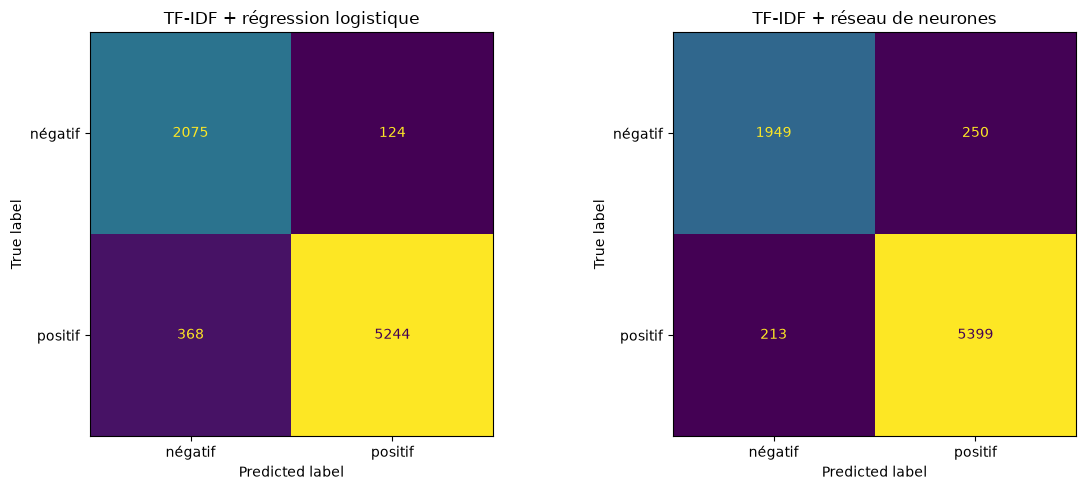

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, nom in enumerate(modeles):
    ConfusionMatrixDisplay.from_predictions(
        y_test, modeles[nom].predict(X_test), display_labels=["négatif", "positif"],
        ax=axes[i], colorbar=False,
    )
    axes[i].set_title(nom)
plt.tight_layout()
plt.show()

## 3. Interprétation : les mots qui comptent

La régression logistique donne un **coefficient par mot** : très positif = le mot pousse vers un avis positif, très négatif = vers un avis négatif.

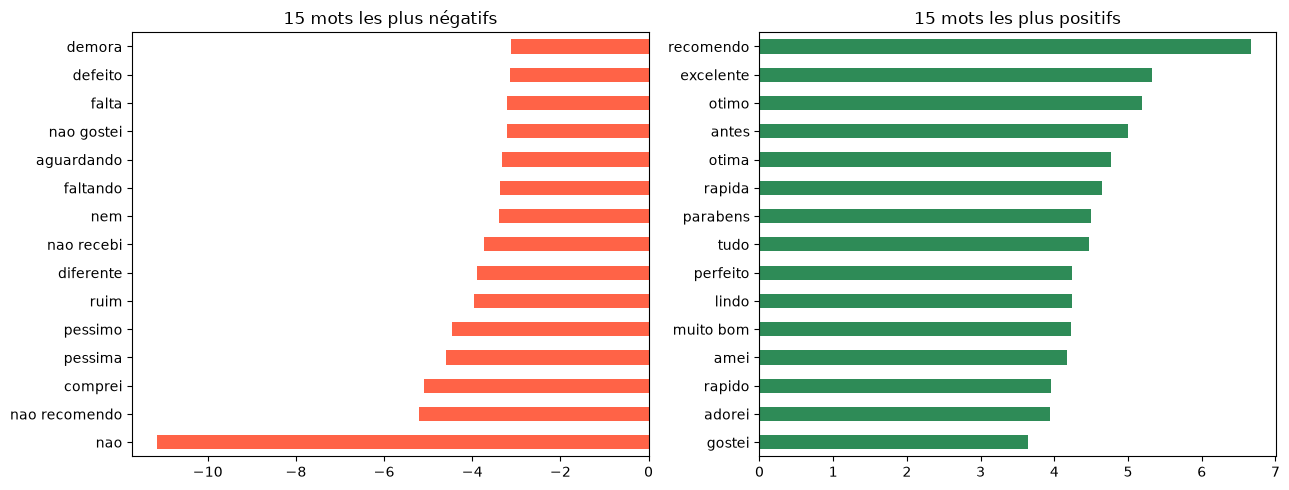

In [6]:
mots = baseline.named_steps["tfidf"].get_feature_names_out()
coefficients = pd.Series(baseline.named_steps["modele"].coef_[0], index=mots)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
coefficients.sort_values().head(15).plot.barh(ax=axes[0], color="tomato")
axes[0].set_title("15 mots les plus négatifs")
coefficients.sort_values().tail(15).plot.barh(ax=axes[1], color="seagreen")
axes[1].set_title("15 mots les plus positifs")
plt.tight_layout()
plt.show()

**Interprétation** :
- **Mots négatifs** : « nao » est de loin le mot le plus négatif, ce qui confirme qu'il fallait **garder la négation** dans le nettoyage. On retrouve aussi « nao recomendo », « nao recebi », « pessimo », « ruim », « defeito », « demora », « aguardando » (j'attends) et « faltando » (il manque). Les problèmes de **livraison** (non reçu, attente, colis incomplet) dominent.
- **Mots positifs** : « recomendo », « excelente », « otimo », mais aussi « antes » (avant la date), « rapida » et « rapido ». La **rapidité de livraison** est l'un des premiers motifs de satisfaction.
- Ces résultats rejoignent l'EDA : la logistique est au cœur de la satisfaction client.

## 4. Exemples de prédictions

In [7]:
exemples = [
    "Produto excelente, chegou antes do prazo!",
    "Não recebi o produto até agora, péssimo.",
    "O produto é bom mas a entrega atrasou muito.",
    "Não gostei, veio com defeito.",
]
for texte in exemples:
    print(texte, "->", predire_sentiment(reseau, texte))

Produto excelente, chegou antes do prazo! -> {'sentiment': 'positif', 'probabilite_positif': 0.998}
Não recebi o produto até agora, péssimo. -> {'sentiment': 'négatif', 'probabilite_positif': 0.004}
O produto é bom mas a entrega atrasou muito. -> {'sentiment': 'positif', 'probabilite_positif': 0.967}
Não gostei, veio com defeito. -> {'sentiment': 'négatif', 'probabilite_positif': 0.025}


## 5. Modèle final

Le modèle retenu (**TF-IDF + régression logistique**) est réentraîné sur **tous** les avis et enregistré dans `models/modele_sentiment.joblib` (non versionné, régénéré par ce notebook). C'est ce fichier que l'API chargera.

In [ ]:
modele_final = entrainer_et_sauvegarder(creer_baseline(), X, y)

## 6. Limites

- **Avis nuancés** : « O produto é bom mas a entrega atrasou muito » (le produit est bon mais la livraison a beaucoup tardé) est classé **positif**. Le modèle compte les mots positifs et négatifs sans comprendre leur articulation (« mas », mais). Un modèle de langue pré-entraîné ferait mieux, au prix d'une infrastructure plus lourde.
- **Notes de 3 exclues** : le modèle ne sait dire que positif ou négatif, pas « neutre ».
- **Seulement 40 % des avis** ont un commentaire écrit : le modèle ne s'applique pas aux avis sans texte (pour ceux-là, la note suffit).
- **Label approximatif** : la note ne reflète pas toujours le texte (par exemple, une note de 5 avec un commentaire critique).
- **Ironie et fautes de frappe** : non gérées.